<a href="https://colab.research.google.com/github/Wael-2/Fashion-MNIST-CNN/blob/main/Fashion_MNIST_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fashion-MNIST Image Classification with a CNN

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2. Imports and reproducibility

In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Reproducibility settings for CUDA/cuDNN operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## 3. Load Fashion-MNIST

Fashion-MNIST contains 28×28 grayscale images and 10 clothing categories.

In [3]:
DATA_DIRECTORY = "/content/drive/MyDrive/FashionMNIST"

# Mean and standard deviation commonly used for Fashion-MNIST
FASHION_MEAN = (0.2860,)
FASHION_STD = (0.3530,)

# Data augmentation for training images
train_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(FASHION_MEAN, FASHION_STD)
])

# No random augmentation for test images
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(FASHION_MEAN, FASHION_STD)
])

train_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_DIRECTORY,
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_DIRECTORY,
    train=False,
    download=True,
    transform=test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4096,
    shuffle=False
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

Training images: 60000
Test images: 10000


## 4. Visualize Fashion-MNIST Samples

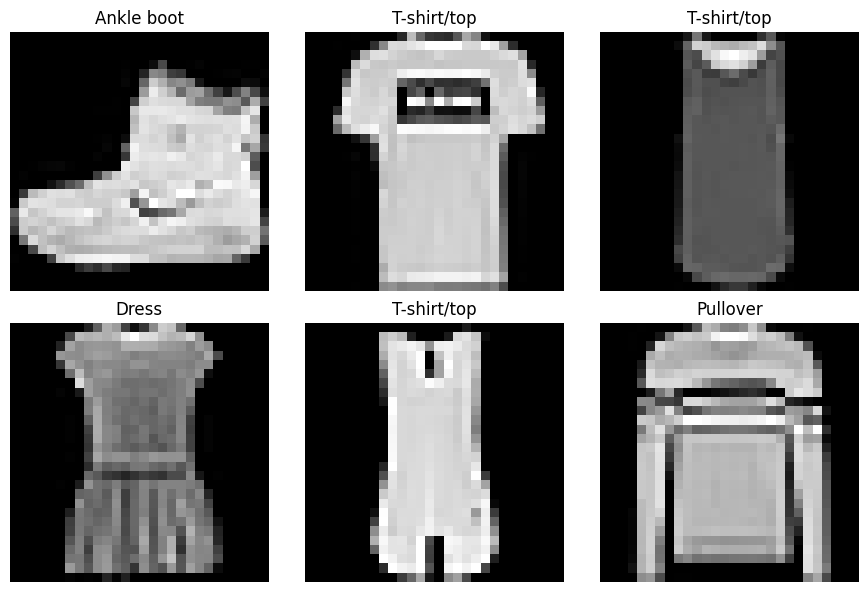

In [4]:
# Load images without augmentation or normalization
raw_train_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_DIRECTORY,
    train=True,
    download=False,
    transform=transforms.ToTensor()
)

fig, axes = plt.subplots(2, 3, figsize=(9, 6))

for i, ax in enumerate(axes.flat):
    image, label = raw_train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Define the CNN

The convolution and pooling layers reduce a 28×28 image to a 50×4×4 feature map. The first fully connected layer therefore receives 50 × 4 × 4 = 800 values.

In [5]:
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # Fashion-MNIST images have 1 channel (grayscale)
        self.conv1 = nn.Conv2d(1, 20, kernel_size=5)
        self.conv2 = nn.Conv2d(20, 50, kernel_size=5)

        self.fc1 = nn.Linear(50 * 4 * 4, 512)
        self.fc2 = nn.Linear(512, 10)

    def forward(self, x):

        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)

        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

## 6. Set device and initialize the model

In [6]:
COMPUTATION_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CNN().to(COMPUTATION_DEVICE)

print("Device:", COMPUTATION_DEVICE)

Device: cuda


## 7. Loss function and evaluation

In [7]:
criterion = nn.CrossEntropyLoss()


def test_model(model, dataloader):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(COMPUTATION_DEVICE)
            labels = labels.to(COMPUTATION_DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

## 8. Configure optimizer and training

In [8]:
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=0.0005
)

# Reduce the learning rate during training
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[10, 15],
    gamma=0.2
)

# Start with 20 epochs (training time depends on whether a GPU is available.)
num_epochs = 20

train_losses = []
test_losses = []

train_accuracies = []
test_accuracies = []

In [9]:
for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(COMPUTATION_DEVICE)
        labels = labels.to(COMPUTATION_DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    test_loss, test_accuracy = test_model(model, test_loader)

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    scheduler.step()

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy * 100:.2f}% "
        f"Test Loss: {test_loss:.4f} "
        f"Test Accuracy: {test_accuracy * 100:.2f}%"
    )

Epoch [1/20] Train Loss: 1.1399 Train Accuracy: 58.48% Test Loss: 0.6947 Test Accuracy: 71.60%
Epoch [2/20] Train Loss: 0.6717 Train Accuracy: 74.05% Test Loss: 0.5685 Test Accuracy: 78.07%
Epoch [3/20] Train Loss: 0.5962 Train Accuracy: 77.01% Test Loss: 0.5195 Test Accuracy: 80.52%
Epoch [4/20] Train Loss: 0.5400 Train Accuracy: 79.56% Test Loss: 0.4851 Test Accuracy: 81.76%
Epoch [5/20] Train Loss: 0.5019 Train Accuracy: 81.08% Test Loss: 0.4298 Test Accuracy: 83.90%
Epoch [6/20] Train Loss: 0.4711 Train Accuracy: 82.34% Test Loss: 0.4197 Test Accuracy: 84.53%
Epoch [7/20] Train Loss: 0.4432 Train Accuracy: 83.52% Test Loss: 0.3937 Test Accuracy: 85.54%
Epoch [8/20] Train Loss: 0.4228 Train Accuracy: 84.34% Test Loss: 0.3726 Test Accuracy: 86.33%
Epoch [9/20] Train Loss: 0.4094 Train Accuracy: 84.80% Test Loss: 0.3558 Test Accuracy: 86.65%
Epoch [10/20] Train Loss: 0.3901 Train Accuracy: 85.53% Test Loss: 0.3591 Test Accuracy: 86.51%
Epoch [11/20] Train Loss: 0.3577 Train Accuracy: 

## 9. Plot training results

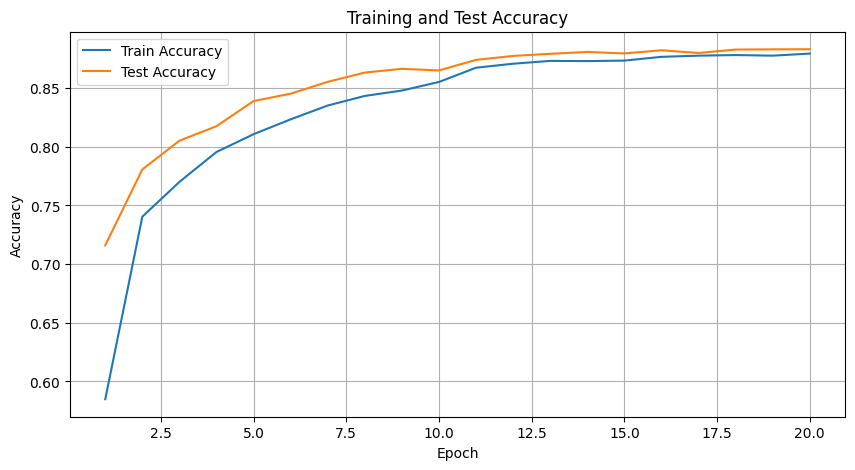

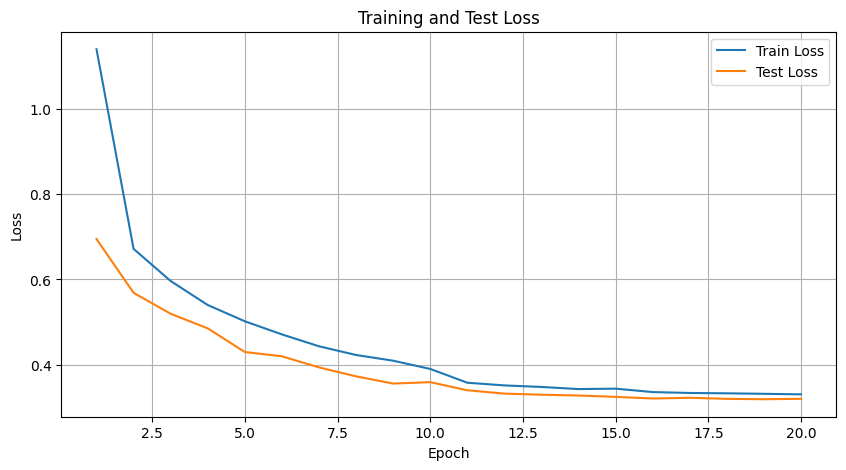

In [10]:
# Accuracy
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_accuracies) + 1), train_accuracies, label="Train Accuracy")
plt.plot(range(1, len(test_accuracies) + 1), test_accuracies, label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Test Accuracy")
plt.legend()
plt.grid()
plt.show()

# Loss
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, label="Train Loss")
plt.plot(range(1, len(test_losses) + 1), test_losses, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Test Loss")
plt.legend()
plt.grid()
plt.show()

## 10. Final test evaluation

In [11]:
test_loss, test_accuracy = test_model(model, test_loader)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.3200
Test Accuracy: 88.32%
